# EDA de variables externas y su relación con la producción

**Proyecto BCR · Lab 2 · Épica E3 (SCRUM-28)**

Historia de usuario: como equipo de Data Science necesitamos explorar las
variables externas y su relación con la producción para **preseleccionar** las
que entran al modelo. Esta tarea **no** incorpora todavía variables a los
modelos; deja una lista de candidatas con un rezago recomendado.

## Qué hacemos acá

1. Estadística descriptiva y gráficos de cada variable.
2. **Correlación cruzada (CCF)** con la producción para rezagos de **0 a 12
   meses**, sobre series **diferenciadas y desestacionalizadas**: la variación
   mensual en log quita la tendencia, y restar la media de cada mes calendario
   quita la estacionalidad. Las dos cosas juntas evitan correlaciones espurias
   (varias series —caña, bioetanol total, pizarra— son estacionales, y sin
   sacar la estacionalidad la CCF queda inflada).
3. Respetamos la **tabla de disponibilidad temporal** (SCRUM-26,
   `data/disponibilidad_variables.csv`) al elegir el rezago: de nada sirve una
   correlación en un rezago al que no vamos a tener acceso al pronosticar.
4. Limitamos la elección a **rezagos con mecanismo** (0–3 meses y 12), para no
   quedarnos con un cruce de la banda por azar entre los 13 rezagos probados.

> **Nota de alcance.** Las series de precio están en **pesos nominales**
> (arrastran inflación). Al diferenciar en log se saca la tendencia, y como la
> producción es física (tn / m³, no pesos), la comovimiento inflacionario no
> genera correlación espuria directa. Aun así, para modelar conviene evaluar
> versiones deflactadas.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = RAIZ / "data"
VEXT = RAIZ / "variables_externas" / "data"
OUT = RAIZ / "results"
OUT.mkdir(exist_ok=True)
print("Raíz:", RAIZ)

Raíz: c:\Users\juanc\Facultad\3er Año\BCR


## 1. Carga de datos

### Series objetivo (producción)

Son las cuatro series que hay que pronosticar: biodiesel (tn) y bioetanol
total, de maíz y de caña (m³). **Recortamos cada serie a su inicio de
entrenamiento del protocolo** (`evaluacion.py`): bioetanol total y caña arrancan
en 2013, no antes, para que la CCF se calcule sobre el mismo tramo que después
usan los modelos (no sobre el arranque ruidoso 2009–2012).

In [2]:
def serie_mensual(df, col):
    s = (df.assign(fecha=pd.to_datetime(df["fecha"]))
           .set_index("fecha")[col].sort_index().astype(float))
    return s[~s.index.duplicated()]

# Inicio de entrenamiento por serie (igual que el protocolo de evaluación).
inicio_protocolo = {
    "biodiesel":       "2008-01",
    "bioetanol_total": "2013-01",
    "bioetanol_maiz":  "2012-09",
    "bioetanol_cana":  "2013-01",
}

bd = pd.read_csv(DATA / "produccion_biodiesel.csv")
be = pd.read_csv(DATA / "produccion_bioetanol.csv")

crudos = {
    "biodiesel":       serie_mensual(bd, "produccion_tn"),
    "bioetanol_total": serie_mensual(be, "produccion_total_m3"),
    "bioetanol_maiz":  serie_mensual(be, "produccion_maiz_m3"),
    "bioetanol_cana":  serie_mensual(be, "produccion_cana_m3"),
}
objetivos = {n: s[s.index >= pd.Timestamp(inicio_protocolo[n])] for n, s in crudos.items()}
for n, s in objetivos.items():
    print(f"{n:16s}: {s.index.min():%Y-%m} → {s.index.max():%Y-%m}  ({len(s)} meses, desde {inicio_protocolo[n]})")

biodiesel       : 2008-01 → 2026-08  (224 meses, desde 2008-01)
bioetanol_total : 2013-01 → 2026-08  (164 meses, desde 2013-01)
bioetanol_maiz  : 2012-09 → 2026-08  (168 meses, desde 2012-09)
bioetanol_cana  : 2013-01 → 2026-08  (164 meses, desde 2013-01)


### Variables externas candidatas

Las cargamos de los **dos relevamientos**:

- **Ya estaban en el repo** (precio, TC, pizarra), en `data/` — documentadas en
  `docs/fuentes_series.md` (Flor).
- **Nuevas de SCRUM-25** (molienda de soja, ventas de gasoil/nafta), en
  `variables_externas/data/` — documentadas en `variables_externas/README.md`
  (Victoria).

Los dos CSV de SCRUM-25 están **versionados** en el repo (son chicos), así que
el notebook es reproducible en un clon limpio. Si por algún motivo faltan, el
notebook **corta con error** en vez de seguir con una lista incompleta (así no
se pisa `variables_candidatas.csv` con menos filas sin que nadie se entere).

In [3]:
# Cada entrada: (archivo, columna, nombre_legible, origen)
fuentes = [
    (DATA / "tipo_cambio_mensual.csv",    "tc_promedio_mes",            "tipo_cambio",            "repo"),
    (DATA / "soja_maiz_cac_mensual.csv",  "soja_ars_tn",               "precio_soja_pizarra",    "repo"),
    (DATA / "soja_maiz_cac_mensual.csv",  "maiz_ars_tn",               "precio_maiz_pizarra",    "repo"),
    (DATA / "biodiesel_precios.csv",      "precio_ars_tn",             "precio_biodiesel",       "repo"),
    (DATA / "bioetanol_precios.csv",      "precio_cana_ars_l",         "precio_bioetanol_cana",  "repo"),
    (DATA / "bioetanol_precios.csv",      "precio_maiz_ars_l",         "precio_bioetanol_maiz",  "repo"),
    (VEXT / "soja_mensual.csv",           "molienda_soja_tn",          "molienda_soja",          "SCRUM-25"),
    (VEXT / "combustibles_mensual.csv",   "ventas_gasoil_grados1a3_m3","ventas_gasoil",          "SCRUM-25"),
    (VEXT / "combustibles_mensual.csv",   "ventas_nafta_grados1a3_m3", "ventas_nafta",           "SCRUM-25"),
]

externas, origen = {}, {}
faltantes = []
for archivo, col, nombre, org in fuentes:
    if archivo.exists():
        externas[nombre] = serie_mensual(pd.read_csv(archivo), col)
        origen[nombre] = org
    else:
        faltantes.append(f"{nombre} ({archivo}, {org})")

if faltantes:
    raise FileNotFoundError(
        "Faltan fuentes de variables externas; no sigo para no generar una "
        "lista incompleta. Deberían estar versionadas en el repo. Faltan:\n  - "
        + "\n  - ".join(faltantes)
    )

print("Variables externas cargadas:")
for n, s in externas.items():
    print(f"  [{origen[n]:8s}] {n:22s}: {s.index.min():%Y-%m} → {s.index.max():%Y-%m}  ({len(s)} meses)")

# Variables que viven en la base unificada (SCRUM-56): derivadas y nuevas fuentes.
# Se agregan a `externas` para que entren a la descriptiva y a los heatmaps.
import sys
sys.path.insert(0, str(RAIZ / "scripts"))
from build_db import leer_dataset
base = leer_dataset()
for sid in ["aceite_soja_usd_tn", "margen_bioetanol_maiz", "margen_domestico_biodiesel"]:
    if sid in base.columns:
        s = base[sid].dropna()
        s.index = pd.to_datetime(s.index)
        externas[sid] = s[~s.index.duplicated()].sort_index()
        origen[sid] = "base"
        print(f"  [base    ] {sid:26s}: {externas[sid].index.min():%Y-%m} -> {externas[sid].index.max():%Y-%m}")


Variables externas cargadas:
  [repo    ] tipo_cambio           : 2018-01 → 2026-09  (105 meses)
  [repo    ] precio_soja_pizarra   : 2018-01 → 2026-09  (105 meses)
  [repo    ] precio_maiz_pizarra   : 2018-01 → 2026-09  (105 meses)
  [repo    ] precio_biodiesel      : 2018-01 → 2026-09  (77 meses)
  [repo    ] precio_bioetanol_cana : 2018-06 → 2026-09  (59 meses)
  [repo    ] precio_bioetanol_maiz : 2018-06 → 2026-09  (59 meses)
  [SCRUM-25] molienda_soja         : 2015-01 → 2026-08  (140 meses)
  [SCRUM-25] ventas_gasoil         : 2010-01 → 2026-08  (200 meses)
  [SCRUM-25] ventas_nafta          : 2010-01 → 2026-08  (200 meses)
  [base    ] aceite_soja_usd_tn        : 1960-01 -> 2026-09
  [base    ] margen_bioetanol_maiz     : 2018-06 -> 2026-09
  [base    ] margen_domestico_biodiesel: 2018-01 -> 2026-09


## 2. Estadística descriptiva

Resumen numérico de cada variable (nivel). Las escalas son muy distintas
(toneladas, m³, $/tn, $/l, $/USD), así que acá solo miramos cada una en sus
propias unidades. La columna `meses_faltantes` cuenta los huecos dentro del
rango de cada serie (importante para los precios regulados).

In [4]:
def meses_faltantes(s):
    grilla = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    return int(grilla.difference(s.index).size)

desc = pd.DataFrame({n: s.describe() for n, s in {**objetivos, **externas}.items()}).T
desc = desc[["count", "mean", "std", "min", "50%", "max"]].rename(columns={"50%": "mediana"})
desc["meses_faltantes"] = [meses_faltantes(s) for s in {**objetivos, **externas}.values()]
desc.round(1)

,count,mean,std,min,mediana,max,meses_faltantes
biodiesel,224.0,150100.0,71069.3,9058.4,142499.0,308897.0,0
bioetanol_total,164.0,83196.1,24709.8,15882.0,84252.4,139521.0,0
bioetanol_maiz,168.0,45846.5,16556.7,3373.0,46726.6,74649.6,0
bioetanol_cana,164.0,36356.4,15058.6,268.2,34138.0,67782.6,0
tipo_cambio,105.0,447.1,522.5,19.0,117.8,1510.6,0
precio_soja_pizarra,105.0,145532.4,166732.7,5133.6,49359.7,558500.0,0
precio_maiz_pizarra,105.0,83609.2,95269.6,2878.4,30302.4,291464.0,0
precio_biodiesel,77.0,583161.7,668601.5,15447.0,185785.0,2012598.0,28
precio_bioetanol_cana,59.0,392.9,402.7,18.0,88.2,1072.5,41
precio_bioetanol_maiz,59.0,364.0,366.8,15.2,107.4,983.0,41


### Gráficos de nivel

Cada variable en el tiempo. Sirve para ver tendencia, estacionalidad y saltos
(p. ej. el desplome de molienda de dic-2020, la caída de ventas en la cuarentena
de 2020, o los saltos escalonados de los precios regulados por inflación).

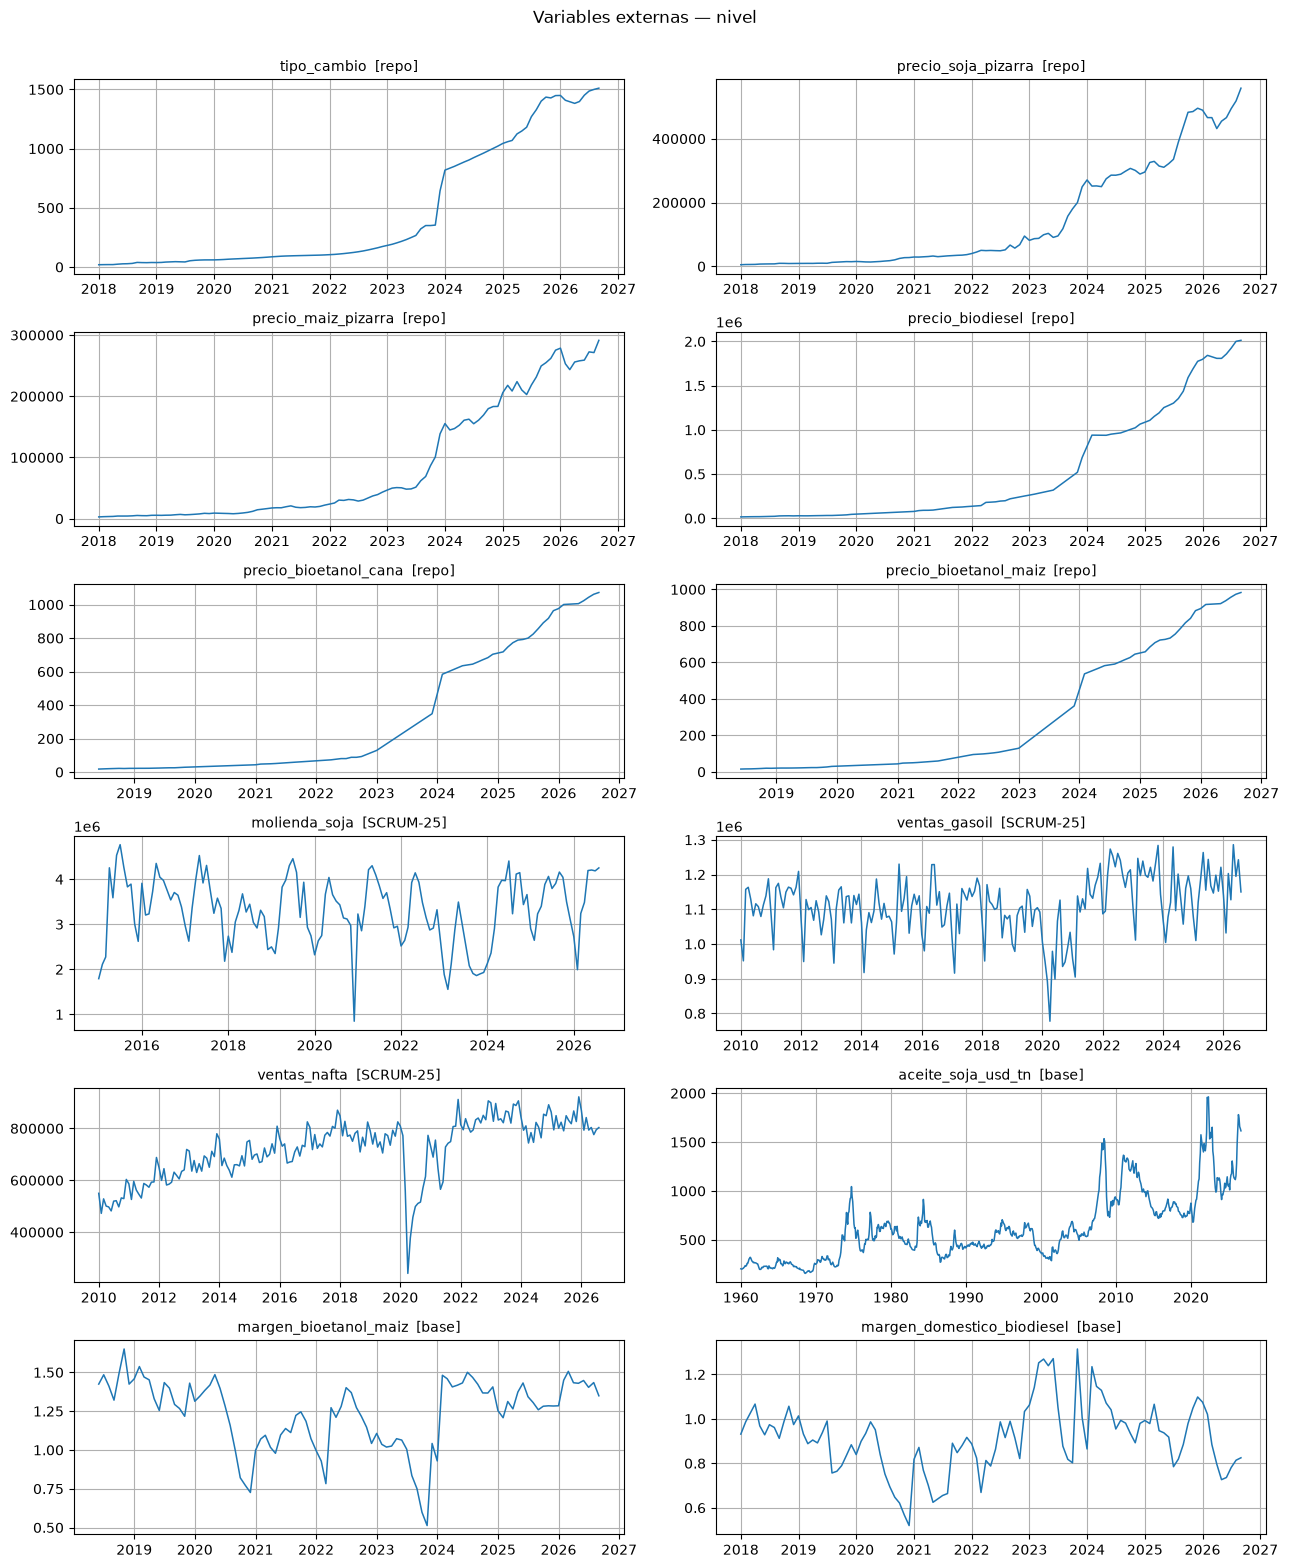

In [5]:
items = list(externas.items())
filas = (len(items) + 1) // 2
fig, axes = plt.subplots(filas, 2, figsize=(13, 2.6 * filas))
for ax, (nombre, s) in zip(axes.ravel(), items):
    ax.plot(s.index, s.values, lw=1.1)
    ax.set_title(f"{nombre}  [{origen[nombre]}]", fontsize=10)
for ax in axes.ravel()[len(items):]:
    ax.axis("off")
fig.suptitle("Variables externas — nivel", y=1.002, fontsize=12)
fig.tight_layout(); plt.show()

## 3. Preparación: diferenciar y desestacionalizar

Dos problemas a sacar antes de correlacionar:

1. **Tendencia.** Casi todas las series suben (los precios, por inflación).
   Correlacionar series con tendencia da correlaciones **espurias**. Se saca con
   la **variación mensual en log** (`Δ log x = log(x_t) − log(x_{t-1})`). El ADF
   lo confirma: en nivel no se rechaza la raíz unitaria, diferenciada sí.
2. **Estacionalidad.** El `Δlog` saca la tendencia pero **no** la
   estacionalidad, y caña, bioetanol total, ventas y pizarra son estacionales.
   Dos series con el mismo patrón estacional "correlacionan" aunque no tengan
   relación. Se saca **restando la media de cada mes calendario** a la serie ya
   diferenciada.

Trabajamos entonces sobre la **variación mensual desestacionalizada** de cada
serie (producción y externas).

> **Huecos en los precios regulados.** Según `docs/fuentes_series.md`, los
> precios regulados tienen meses sin dato (biodiesel 28, bioetanol 41). Una
> `Δlog` que cruza un hueco no es una variación mensual, así que **no
> diferenciamos a través de los huecos**: reindexamos a la grilla mensual y la
> diferencia que toca un faltante queda `NaN`. Esas dos series quedan con `n`
> chico y su CCF se lee con **confianza menor**.

In [6]:
def adf_p(s):
    s = s.dropna()
    if (s <= 0).any() or len(s) < 12:
        return np.nan, np.nan
    nivel = adfuller(s)[1]
    dif = adfuller(np.log(s).diff().dropna())[1]
    return nivel, dif

filas = []
for n, s in {**objetivos, **externas}.items():
    pn, pd_ = adf_p(s)
    filas.append({"variable": n, "p_ADF_nivel": pn, "p_ADF_logdiff": pd_,
                  "nivel_estacionario": pn < 0.05 if pn == pn else None,
                  "logdiff_estacionario": pd_ < 0.05 if pd_ == pd_ else None})
print("p<0.05 ⇒ estacionaria. Esperamos: nivel NO, log-diff SÍ.")
pd.DataFrame(filas).set_index("variable").round(3)

p<0.05 ⇒ estacionaria. Esperamos: nivel NO, log-diff SÍ.


,p_ADF_nivel,p_ADF_logdiff,nivel_estacionario,logdiff_estacionario
variable,,,,
biodiesel,0.251,0.000,False,True
bioetanol_total,0.422,0.000,False,True
bioetanol_maiz,0.248,0.000,False,True
bioetanol_cana,0.345,0.000,False,True
tipo_cambio,0.993,0.000,False,True
precio_soja_pizarra,1.000,0.000,False,True
precio_maiz_pizarra,0.999,0.000,False,True
precio_biodiesel,0.998,0.000,False,True
precio_bioetanol_cana,0.980,0.000,False,True


In [7]:
def logdiff(s):
    """Variación mensual en log, SIN diferenciar a través de huecos."""
    s = s[s > 0].dropna()
    if s.empty:
        return s
    grilla = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    s = s.reindex(grilla)
    return np.log(s).diff().dropna()

def prep(s):
    """Variación mensual en log desestacionalizada (resta la media de cada mes)."""
    d = logdiff(s)
    if d.empty:
        return d
    return d - d.groupby(d.index.month).transform("mean")

obj_d = {n: prep(s) for n, s in objetivos.items()}
ext_d = {n: prep(s) for n, s in externas.items()}

print("Observaciones (variación mensual desestacionalizada) por variable externa:")
for n, s in ext_d.items():
    print(f"  {n:22s}: {len(s):>3} obs")

Observaciones (variación mensual desestacionalizada) por variable externa:
  tipo_cambio           : 104 obs
  precio_soja_pizarra   : 104 obs
  precio_maiz_pizarra   : 104 obs
  precio_biodiesel      :  67 obs
  precio_bioetanol_cana :  47 obs
  precio_bioetanol_maiz :  47 obs
  molienda_soja         : 139 obs
  ventas_gasoil         : 199 obs
  ventas_nafta          : 199 obs
  aceite_soja_usd_tn    : 800 obs
  margen_bioetanol_maiz :  99 obs
  margen_domestico_biodiesel: 104 obs


## 4. Correlación cruzada (CCF) con la producción

Para cada par (variable externa, producción) calculamos la correlación entre
`x` rezagada `k` meses y la producción, para `k = 0 … 12`:

$$\rho_k = \mathrm{corr}\big(x_{t-k},\; y_t\big)$$

Un `k` positivo significa que la variable externa **adelanta** a la producción
en `k` meses (indicador líder). Las dos series ya vienen diferenciadas y
desestacionalizadas.

**Anti-leakage:** la CCF se calcula **solo con datos anteriores a septiembre
2021** (inicio del backtest, SCRUM-43), así ninguna decisión mira el período de
evaluación. Es **exploratoria**: sugiere qué rezago probar, no descarta.

In [8]:
MAX_LAG = 12
CORTE = pd.Timestamp("2021-09-01")  # anti-leakage: la CCF no mira el backtest (SCRUM-43)

def ccf_series(x, y, max_lag=MAX_LAG):
    x = x[x.index < CORTE]
    y = y[y.index < CORTE]
    out = {}
    for k in range(max_lag + 1):
        xk = x.shift(k, freq="MS")
        df = pd.concat([xk, y], axis=1, join="inner").dropna()
        out[k] = (df.iloc[:, 0].corr(df.iloc[:, 1]) if len(df) > 2 else np.nan, len(df))
    return out

def tabla_ccf(target_d, ext_d):
    corr, n = {}, {}
    for nombre, x in ext_d.items():
        res = ccf_series(x, target_d)
        corr[nombre] = {k: v[0] for k, v in res.items()}
        n[nombre] = {k: v[1] for k, v in res.items()}
    return pd.DataFrame(corr).T, pd.DataFrame(n).T

print(f"CCF exploratoria, solo con datos < {CORTE:%Y-%m} (anti-leakage).")
print("Convencion: rezago k>0 => la variable externa adelanta a la produccion.")

CCF exploratoria, solo con datos < 2021-09 (anti-leakage).
Convencion: rezago k>0 => la variable externa adelanta a la produccion.


### Heatmaps de CCF por serie objetivo

Una grilla por producción: filas = variables, columnas = rezago (0 a 12). Rojo =
positiva, azul = negativa. Calculada solo con datos **< sep-2021**. Los puntos
marcan las que cruzan ±1,96/√n, pero **la significancia es informativa, no un
filtro**: la selección (§5) es por **mecanismo económico + disponibilidad**.

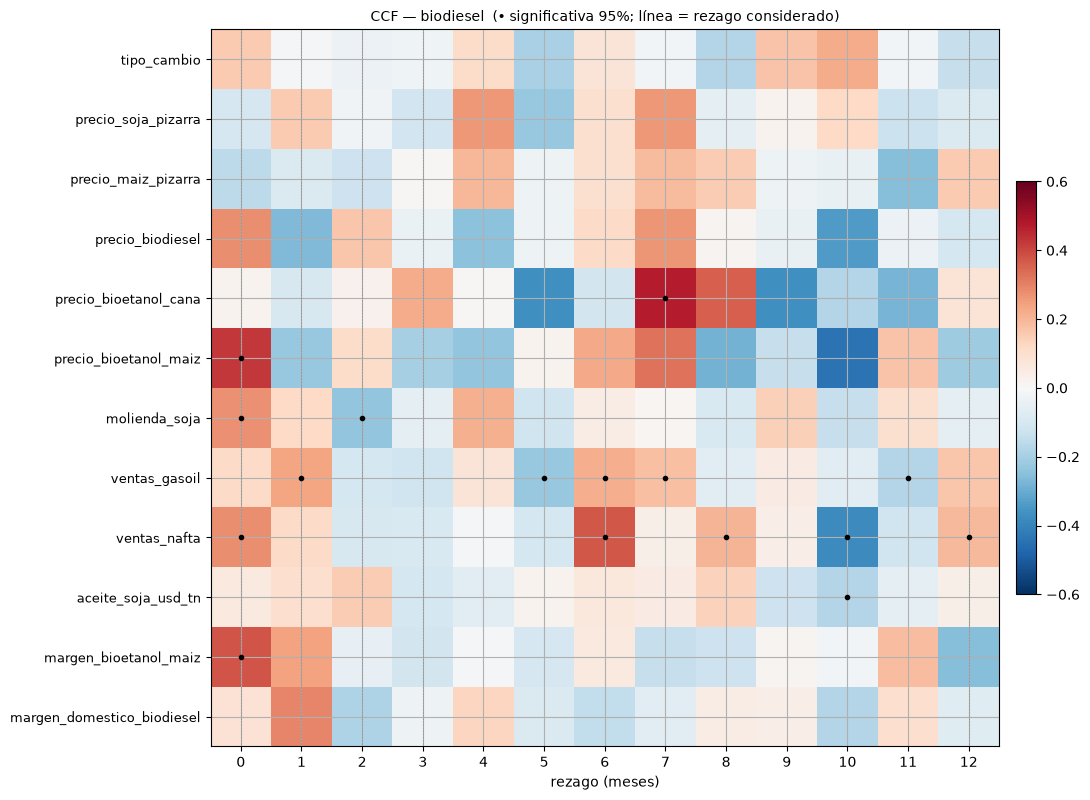

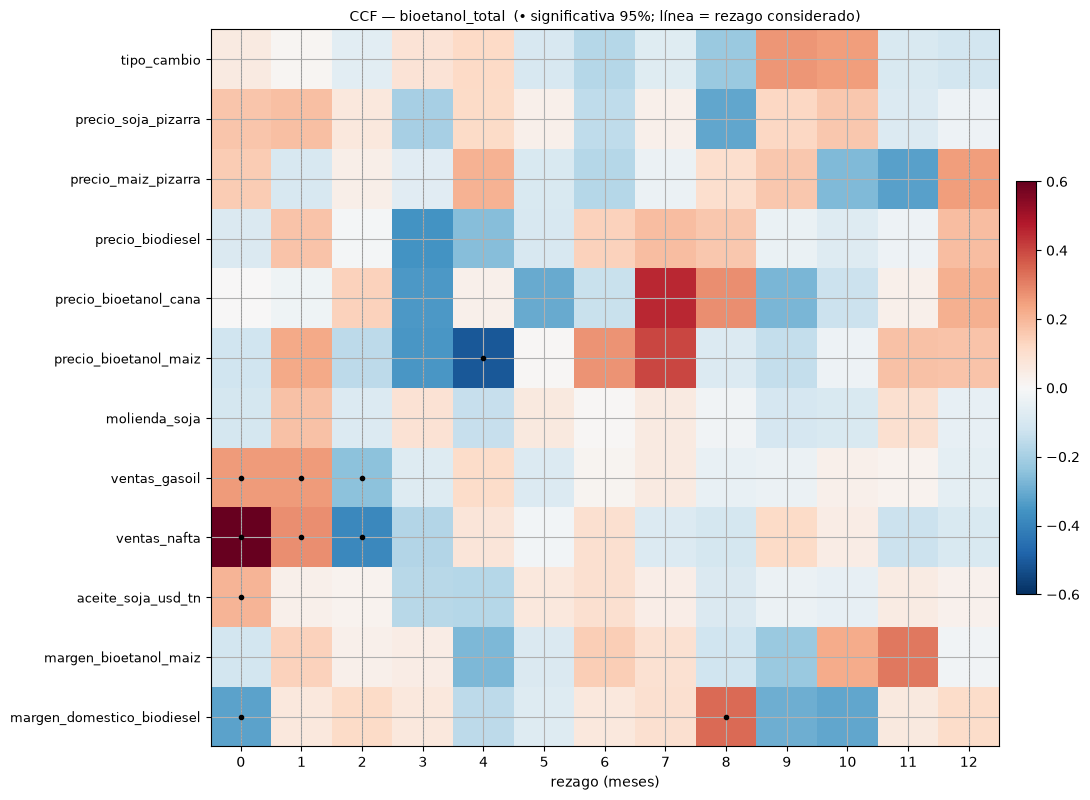

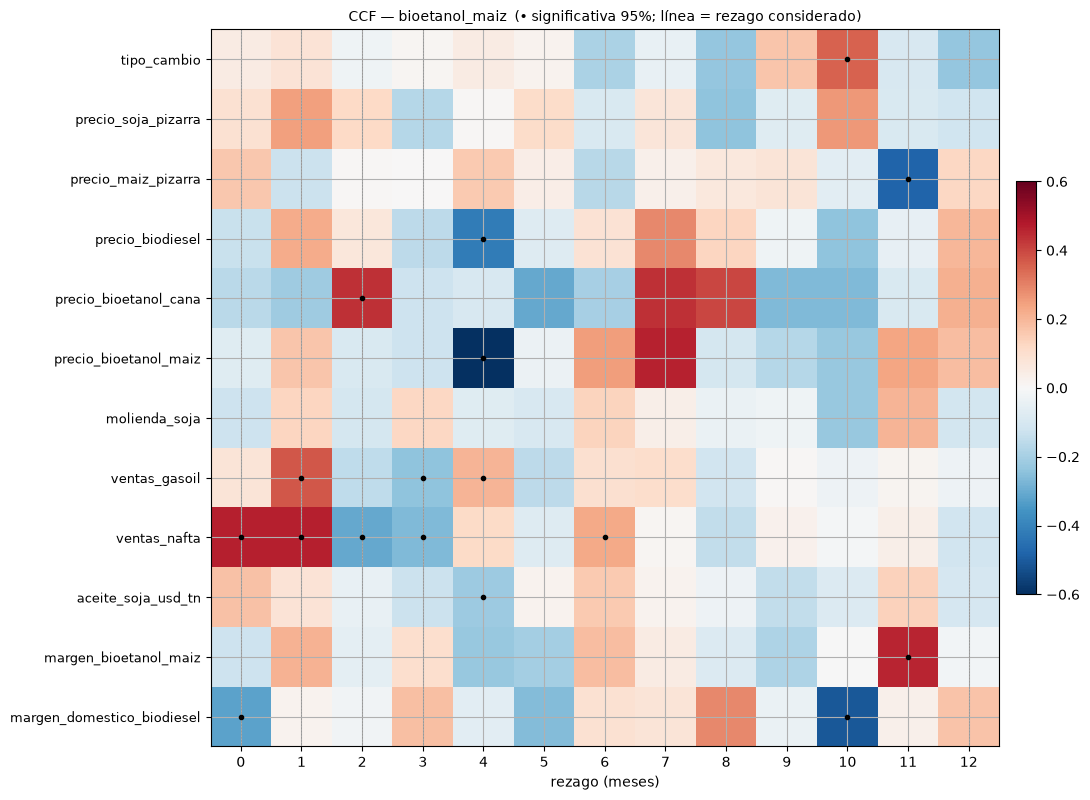

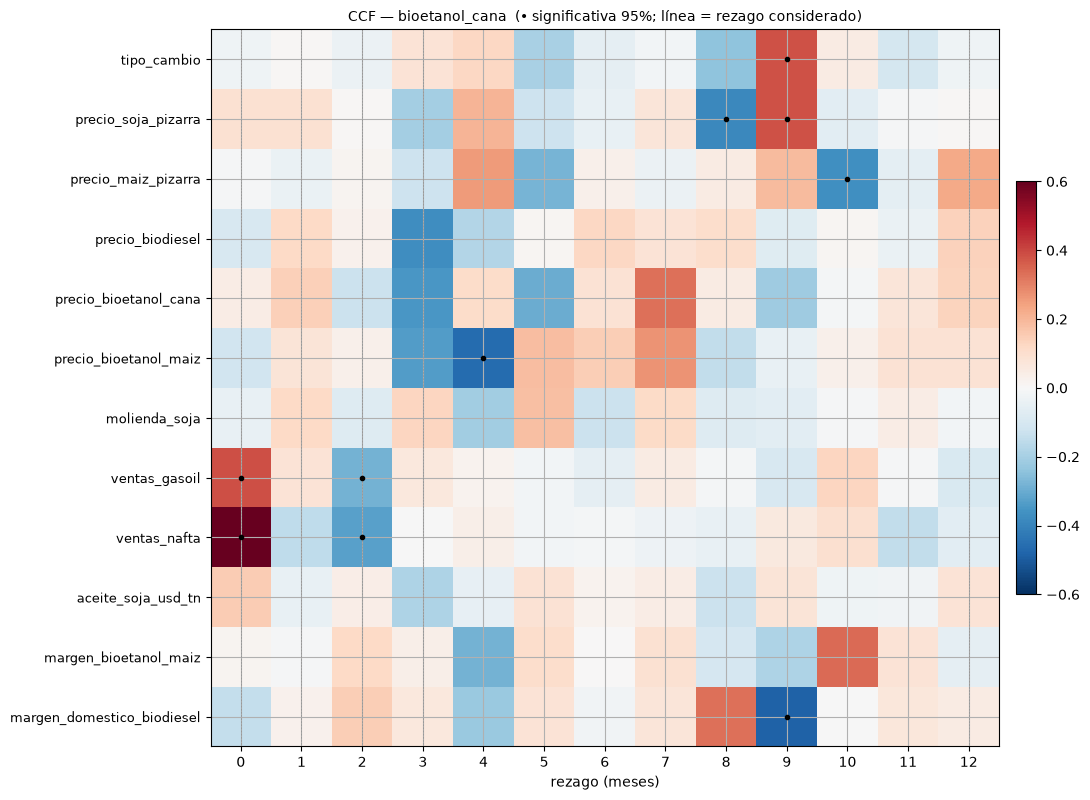

In [9]:
REZAGOS_PERMITIDOS = [0, 1, 2, 3, 12]  # corto plazo + ciclo anual

def heatmap_ccf(nombre_target, target_d):
    corr, n = tabla_ccf(target_d, ext_d)
    banda = 1.96 / np.sqrt(n.replace(0, np.nan))
    sig = corr.abs() > banda
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(corr) + 1.5))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    ax.set_xticks(range(MAX_LAG + 1)); ax.set_xticklabels(range(MAX_LAG + 1))
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=9)
    ax.set_xlabel("rezago (meses)")
    for j in REZAGOS_PERMITIDOS:      # resalta las columnas que la selección usa
        ax.axvline(j, color="k", lw=0.4, ls=":", alpha=0.4)
    for i in range(len(corr)):
        for j in range(MAX_LAG + 1):
            if bool(sig.values[i, j]):
                ax.plot(j, i, "o", ms=3, color="black")
    ax.set_title(f"CCF — {nombre_target}  (• significativa 95%; línea = rezago considerado)", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    fig.tight_layout(); plt.show()
    return corr, n

ccf_tablas = {}
for nombre, td in obj_d.items():
    ccf_tablas[nombre] = heatmap_ccf(nombre, td)

## 5. Selección de candidatas (por mecanismo)

La CCF es **exploratoria**, no un filtro. Con ~100 meses tiene poca potencia y,
con ~180 pruebas, se esperan ~9 "significativas" por azar al 95%. Por eso **no
descartamos por significancia**: una variable es candidata si tiene **mecanismo
económico** y está **disponible a tiempo** (SCRUM-26); la CCF solo sugiere qué
rezago probar.

La CCF anti-leakage (datos < sep-2021) la calcula `scripts/ccf_candidatas.py` y
queda en `results/ccf_candidatas.csv` — **fuente única**, que este notebook
consume en vez de recalcular. La tabla narrada por mecanismo está en
`docs/candidatas_28.md`.

In [10]:
# Fuente unica de la CCF anti-leakage: results/ccf_candidatas.csv (scripts/ccf_candidatas.py).
ccf = pd.read_csv(OUT / "ccf_candidatas.csv")

# rezago_min por serie: serie_id -> variable_disponibilidad (series/derivadas) -> rezago_min.
DB = RAIZ / "db"
disp_tab = pd.read_csv(DATA / "disponibilidad_variables.csv")
rez_disp = dict(zip(disp_tab["variable"], disp_tab["rezago_min"].astype(int)))
cat = pd.concat([
    pd.read_csv(DB / "series.csv")[["serie_id", "variable_disponibilidad"]],
    pd.read_csv(DB / "derivadas.csv")[["serie_id", "variable_disponibilidad"]],
], ignore_index=True)
sid2disp = dict(zip(cat["serie_id"], cat["variable_disponibilidad"]))
def kmin_de(sid):
    return rez_disp.get(sid2disp.get(sid, sid), 1)

# Candidatas por MECANISMO economico, por serie objetivo (ver docs/candidatas_28.md).
candidatas_mecanismo = {
    "biodiesel":       ["margen_domestico_biodiesel", "ventas_gasoil_total_m3",
                        "molienda_soja_tn", "precio_biodiesel_ars_tn"],
    "bioetanol_total": ["ventas_nafta_total_m3", "precio_bioetanol_cana_ars_l",
                        "precio_bioetanol_maiz_ars_l"],
    "bioetanol_maiz":  ["ventas_nafta_total_m3", "margen_bioetanol_maiz",
                        "precio_bioetanol_maiz_ars_l"],
    "bioetanol_cana":  ["ventas_nafta_total_m3", "precio_bioetanol_cana_ars_l"],
}

filas = []
for target, variables in candidatas_mecanismo.items():
    for var in variables:
        hit = ccf[(ccf["target"] == target) & (ccf["variable"] == var)]
        kmin = kmin_de(var)
        fila = {"target": target, "variable": var, "rezago_min_disp": kmin,
                "mejor_rezago_ccf": None, "corr_ccf": None, "n_ccf": None}
        if not hit.empty:
            r = hit.iloc[0]
            fila.update(mejor_rezago_ccf=int(r["mejor_rezago"]),
                        corr_ccf=round(float(r["corr"]), 3), n_ccf=int(r["n"]))
        filas.append(fila)

candidatas = pd.DataFrame(filas)
candidatas.to_csv(OUT / "variables_candidatas.csv", index=False)
print("Candidatas por mecanismo guardadas en", OUT / "variables_candidatas.csv")
print("La CCF es orientativa del rezago; la seleccion es por mecanismo + disponibilidad.")
candidatas

Candidatas por mecanismo guardadas en c:\Users\juanc\Facultad\3er Año\BCR\results\variables_candidatas.csv
La CCF es orientativa del rezago; la seleccion es por mecanismo + disponibilidad.


,target,variable,rezago_min_disp,mejor_rezago_ccf,corr_ccf,n_ccf
0,biodiesel,margen_domestico_biodiesel,0,1.0,0.269,42.0
1,biodiesel,ventas_gasoil_total_m3,0,5.0,-0.273,134.0
2,biodiesel,molienda_soja_tn,0,0.0,0.328,79.0
3,biodiesel,precio_biodiesel_ars_tn,0,1.0,0.522,27.0
4,bioetanol_total,ventas_nafta_total_m3,0,2.0,-0.349,137.0
5,bioetanol_total,precio_bioetanol_cana_ars_l,0,NaN,NaN,NaN
6,bioetanol_total,precio_bioetanol_maiz_ars_l,0,NaN,NaN,NaN
7,bioetanol_maiz,ventas_nafta_total_m3,0,0.0,0.507,107.0
8,bioetanol_maiz,margen_bioetanol_maiz,0,11.0,0.399,27.0
9,bioetanol_maiz,precio_bioetanol_maiz_ars_l,0,NaN,NaN,NaN


### Resumen de candidatas por serie

Por mecanismo económico; la CCF (de `results/ccf_candidatas.csv`) es solo
orientativa del rezago. Las de precio regulado van como *baja confianza* por la
ventana corta y los huecos.

In [11]:
for t in candidatas_mecanismo:
    sub = candidatas[candidatas["target"] == t]
    print(f"\n### {t}")
    for _, r in sub.iterrows():
        c = r["corr_ccf"]
        if c is None or pd.isna(c):
            ccf_txt = "CCF s/d"
        else:
            signo = "+" if c > 0 else "-"
            ccf_txt = f"CCF {signo}{abs(c):.2f} @ rz{int(r['mejor_rezago_ccf'])} (n={int(r['n_ccf'])})"
        print(f"  {r['variable']:28s}  rezago_min {int(r['rezago_min_disp'])}  {ccf_txt}")


### biodiesel
  margen_domestico_biodiesel    rezago_min 0  CCF +0.27 @ rz1 (n=42)
  ventas_gasoil_total_m3        rezago_min 0  CCF -0.27 @ rz5 (n=134)
  molienda_soja_tn              rezago_min 0  CCF +0.33 @ rz0 (n=79)
  precio_biodiesel_ars_tn       rezago_min 0  CCF +0.52 @ rz1 (n=27)

### bioetanol_total
  ventas_nafta_total_m3         rezago_min 0  CCF -0.35 @ rz2 (n=137)
  precio_bioetanol_cana_ars_l   rezago_min 0  CCF s/d
  precio_bioetanol_maiz_ars_l   rezago_min 0  CCF s/d

### bioetanol_maiz
  ventas_nafta_total_m3         rezago_min 0  CCF +0.51 @ rz0 (n=107)
  margen_bioetanol_maiz         rezago_min 0  CCF +0.40 @ rz11 (n=27)
  precio_bioetanol_maiz_ars_l   rezago_min 0  CCF s/d

### bioetanol_cana
  ventas_nafta_total_m3         rezago_min 0  CCF +0.57 @ rz0 (n=139)
  precio_bioetanol_cana_ars_l   rezago_min 0  CCF s/d


## 6. Conclusiones y próximos pasos

- La **CCF anti-leakage** (datos < sep-2021) está en `results/ccf_candidatas.csv`
  (`scripts/ccf_candidatas.py`): es la **fuente única**, este notebook la consume.
  La **tabla narrada por mecanismo** está en `docs/candidatas_28.md`.
- **Criterio: mecanismo económico + disponibilidad a tiempo (SCRUM-26), no
  significancia.** Con ~100 meses la CCF tiene poca potencia; solo sugiere el
  rezago, no descarta.
- Las correlaciones son en general **débiles** (ninguna variable es un predictor
  lineal fuerte de la producción en variación mensual). La candidata de mayor
  valor esperado para biodiésel es el **margen doméstico** (SCRUM-51, +0,27 @ rz1);
  para bioetanol, las **ventas de nafta**.
- **Pendiente:** el **corte obligatorio** (SCRUM-48); cuando entre a la base se
  recalcula la CCF y se suma su fila.

**Para el modelado (SCRUM-29 en adelante):**

1. Entran las candidatas por mecanismo, probando los rezagos disponibles
   (0–2 según SCRUM-26), nunca un rezago no disponible → evita fuga de información.
2. Correlación ≠ causalidad ≠ mejora predictiva: la preselección reduce el
   espacio de búsqueda; el aporte real se mide con el **walk-forward** del
   protocolo (SCRUM-43/54), comparando el modelo con y sin cada variable.